<h3><center>Introduction to Building a Quant Pricing Library</center></h3>
<h1><center>Volatility Surface, Numerical Greeks</center></h1>
<h3><center>Tamas Glatz</h3>
<h3><center>(Based on Gabor Friedmann's Lecutre Notes)</center></h3>
<h4><center>14 October, 2026</center></h4>


### <b> The law of supply and demand:</b>
* Number of people who want to buy go $ \uparrow $, or want to sell go $ \downarrow $ $\Longrightarrow $ Price goes $\uparrow$
* Number of people who want to buy go $ \downarrow $, or want to sell go $ \uparrow $ $\Longrightarrow $ Price goes $\downarrow $
* This simple dynamic drives the price of many goods... For example
    * Market price of face masks during covid
    * <b> Market price of options<b> (quotes)

## <b>Goal of option pricing:</b>
* Come up with a model that is able to re-price "frequently traded" (liquid) products
* Use the model to understand how to eliminate risks (hedging)
* Use the model to price other, "non-frequently traded" (illiquid) products

# Moneyness

Measures whether the option would make money if it were exercised immediately. We define moneyness as current spot price divided by strike price:
$$ M = \dfrac{S_t}{K} $$

At $M = 1$, the option is called at-the-money (ATM). Otherwise, the option is called either in-the-money (ITM) or out-of-the-money (OTM).

<img src="./img/moneyness.jpg" style="margin-left:auto; margin-right:auto; width: 1000px;" />

## What did we learn?

Black-Scholes model assumptions:
* Underlying asset price follows GBM:

$$ dS_{t}=\mu S_{t}\,dt+\sigma S_{t}\,dW_{t} $$
* Underlying asset price has <b>known and constant</b> volatility ($\sigma$)
* Log returns of the underlying asset are normally distributed

### Under these assumptions we can derive the price of a European Call option $c_0$ (by ruling out arbitrage):

$$
c_0 = S_0 N(d_1) - K e^{-rT} N(d_2)
$$
where
$$
d_1 = \frac{\ln\left(\frac{S_0}{K}\right) + \left(r + \frac{\sigma^2}{2}\right)T}{\sigma\sqrt{T}}; \, d_2 = d_1 - \sigma\sqrt{T}
$$
So essentially $c_0$ is a function of 5 parameters:
$$
c_0 = f_{BS}\left(S_0, K, T, r, {\sigma}\right)
$$
#### Which of these parameters are known to us?

#### Remember, our goal with the model is NOT to determine how much the option we observe should cost, but to know how to hedge it.

$$ \color{red}{\sigma} = f^{-1}_{BS}\left(S_0, K, T, r, c_0\right) $$

<b>Implied volatility</b>: The volatility obtained from market quotes using Black-Scholes formula. It represents what the market is implying the volatility will be in the future based on option prices.

#### Based on BS assumptions, implied volatility should be constant for all options on a given underlying. Is that true?

<img src="./img/implied_vol_smile.jpg" style="margin-left:auto; margin-right:auto; width: 1500px;" />

<img src="./img/smile_skew.jpg" style="margin-left:auto; margin-right:auto; width: 1500px;" alt="Source: https://analystprep.com/study-notes/frm/part-2/market-risk-measurement-and-management/volatility-smiles/" />

## Why?

Highligting just one concept: Protective Put Option Strategy

There is high demand for put options with low strike as they serve as a protection against huge losses.

<img src="./img/protective_put.jpg" style="margin-left:auto; margin-right:auto; width: 400px;" />


<img src="./img/implied_vol_termskew.jpg" style="margin-left:auto; margin-right:auto; width: 1500px;" />

<b>Conclusion</b>: The volatility in our model should depend on strike and expiry: <b>$ \sigma = \sigma(K,T) $<b>

Using market quotes, we can derive an <b>implied volatility grid</b>. Applying some interpolation technique between grid points we can build an <b>implied volatility surface</b>.

Let's look at some examples!

BlueChip Bank, TipTop Solutions, Money Mall


In [7]:
# Add current folder and QuantCourseBP folder to syspath to import modules
import sys
import numpy as np
from pathlib import Path
current = Path(Path().resolve())
sys.path.append(str(current))
sys.path.append(str(current.parents[2]))

from src.utils import *
from src.market_data import *

# Make charts interactive - remove this line if charts throws error
%matplotlib widget

# Initialize market data
MarketData.initialize()

QuantCourseBP 802cd9134002f8bacc0d51a13f562bd26bdec641*


In [8]:
underlying = Stock.BLUECHIP_BANK
volgrid = MarketData.get_volgrid()[underlying]

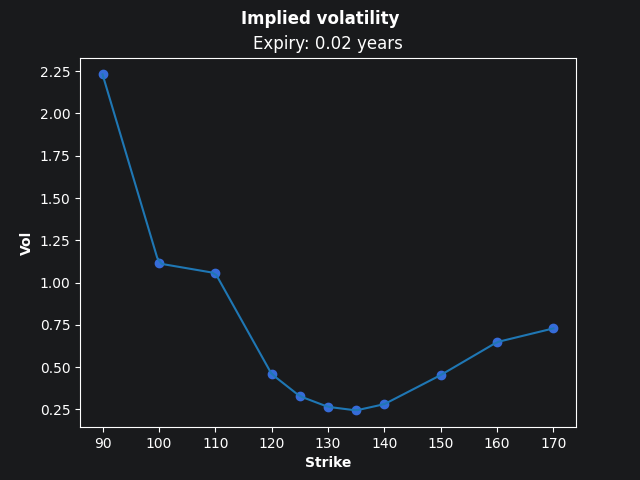

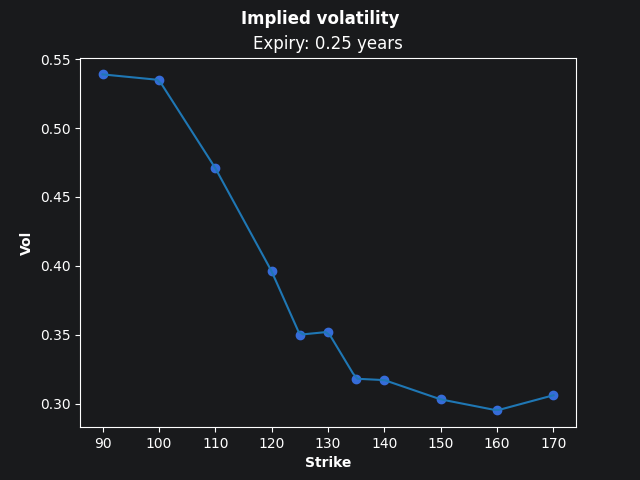

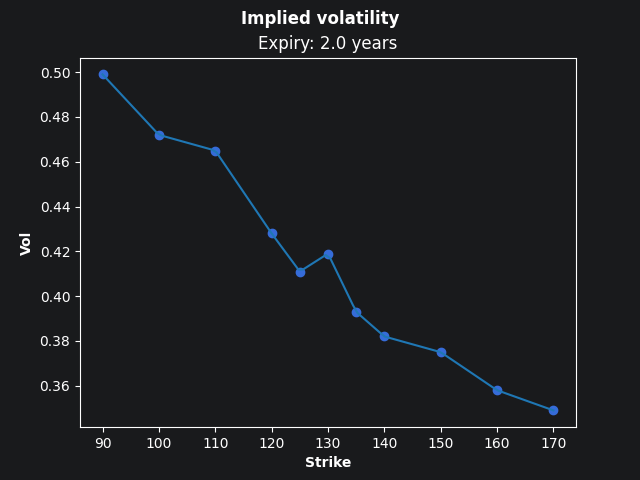

In [9]:
flag = True
plot_vol_slice(volgrid, expiry=0.02, linear_interpolation=flag) # 7D
plot_vol_slice(volgrid, expiry=0.25, linear_interpolation=flag) # 3M
plot_vol_slice(volgrid, expiry=2.00, linear_interpolation=flag) # 2Y

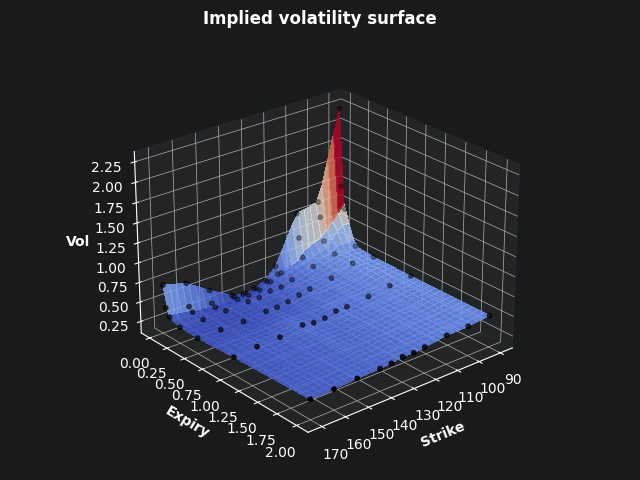

In [10]:
plot_vol_surface(volgrid)

## What changes?

Underlying asset price diffusion:
$$ \; dS_{t}=\mu S_{t}\,dt+\sigma S_{t}\,dW_{t} $$


$$ \; dS_{t}=\mu S_{t}\,dt+\color{red}{\sigma(K,T)} S_{t}\,dW_{t} $$

We can determine $ \sigma(K,T) $ based on the contract we want to price, then use that constant within the Black-Scholes framework. Let's call this extension of BS model as <b>flat volatility model</b>.

Volatility market data is no longer a single number, but a tabular data (grid) for each underlying, hence we outsource them to csv files for maintainability.

<br>
<br>

Let's do coding!

# Tasks

## MarketData - market_data.py

* Understand the new structure of MarketData class
* Understand how VolGrid class works

## MarketModel - model.py

* Implement BSVol and FlatVol models in the pricing library

## Jupyter notebook

* Price a few contracts using both Black-Scholes and FlatVol models

In [11]:
# Add current folder and QuantCourseBP folder to syspath to import modules
import sys
from pathlib import Path
current = Path(Path().resolve())
sys.path.append(str(current))

for p in [str(current.parents[2]),str(current.parents[2]/"src") ]:
    if p in sys.path:
        sys.path.remove(p)

from market_data import MarketData
from pricer import *
from model import *

In [12]:
und = Stock.BLUECHIP_BANK
put_call = PutCallFwd.CALL
ls = LongShort.LONG
strike = 1.0 * MarketData.get_spot()[und] # at-the-money strike i.e. strike = spot price
strike_itm = strike * 1.1
exp = 1

forward = ForwardContract(und, ls, strike, exp)
option = EuropeanContract(und, put_call, ls, strike , exp)
option_itm = EuropeanContract(und, put_call, ls, strike_itm, exp)

print(option)

{'underlying': <Stock.BLUECHIP_BANK: 'BLUECHIP_BANK'>, 'type': <PutCallFwd.CALL: 'CALL'>, 'long_short': <LongShort.LONG: 'LONG'>, 'strike': 130.17, 'expiry': 1}


# Greeks

* Understanding the sensitivities of a porfolio is crutial to eliminate them (hedging)
* So far we had analytical formulas to calculate greeks, usually this is not the case
* In most cases we calculate greeks numerically using finite difference approximation (forward, backward, central)

## Finite difference approximation (central, absolute)
$$ f'(x)\approx\dfrac{f(x+\Delta)-f(x-\Delta)}{2\Delta} $$

$$ f''(x)\approx\dfrac{f'(x+\dfrac{\Delta}{2})-f'(x-\dfrac{\Delta}{2})}{\Delta}\approx\dfrac{f(x+\Delta)-2f(x)+f(x-\Delta)}{\Delta^2} $$

# Tasks

## Pricer - pricer.py

* Implement calc_delta() function using finite difference approximation.
* Compare the results of analytic and numerical formulas for delta and gamma.

# Assignments - Numerical greeks

1. Introduce two class variables in Pricer that store the finite difference method (forward, backward, central) to be used in numerical greek calculation, and whether the bump size is absolute or relative. Create two Enums to store the labels. Implement all combinations for delta and gamma calculation.<br>Compare greeks using the analytic and the finite difference approximation on a set of European options and visualize the numerical error. Compare absolute and relative bumping and suggest optimal bump sizes. **(15 points)**